# Prediksi Close TRXUSDT dengan BiLSTM

(perlu merubah proposal dari 1d menjadi 1h, karena paper yang saya temukan menemukan bahwa sliding window 25 paling bagus, dan mereka menggunakan interval 1h)


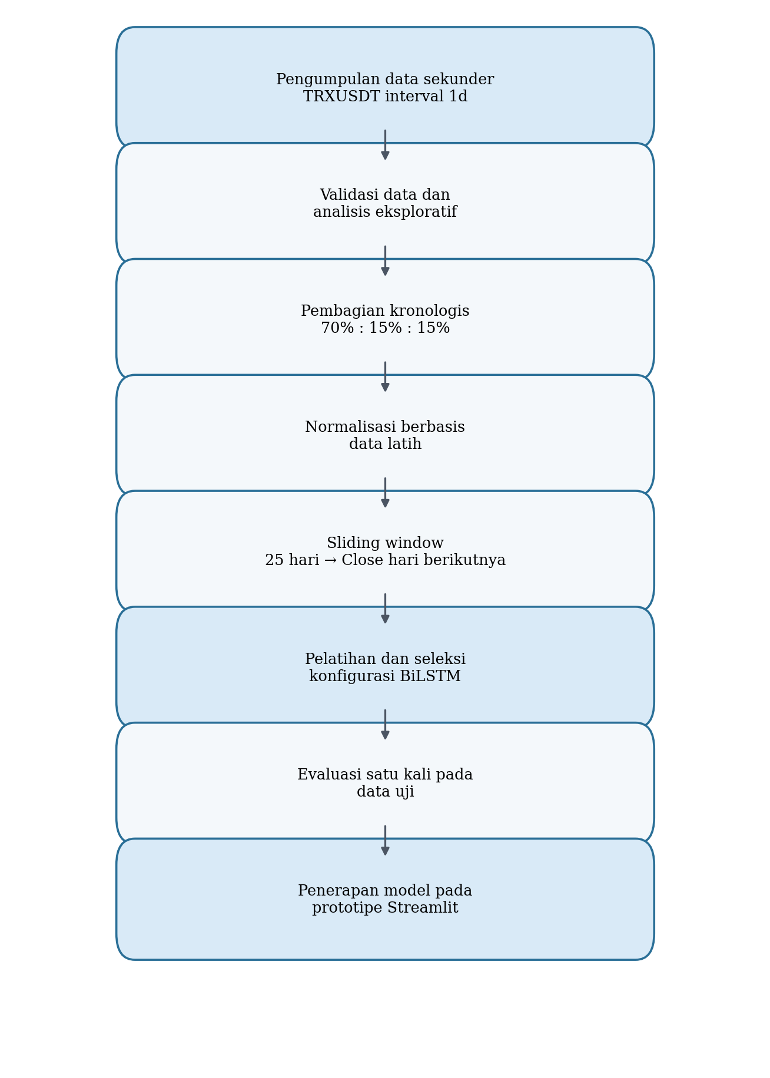

In [1]:
%pip install -r requirements.txt

In [2]:
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
import inspect
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Code, display

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "trx_bilstm.py").is_file():
    raise FileNotFoundError("Buka notebook dari folder paket yang berisi trx_bilstm.py.")
sys.path.insert(0, str(PROJECT_DIR))

from trx_bilstm import (
    BASE_URL, FEATURES, FORECAST_HORIZON, INTERVAL, SYMBOL, TARGET, WINDOW_SIZE,
    BiLSTMRegressor, ModelConfig, choose_device, environment_versions,
    evaluate_test, fetch_hourly, file_sha256, fit_model, load_bundle,
    predict_next, prepare_data, save_bundle, tune_model, validate_frame, write_json,
)
sns.set_theme(style="whitegrid")
print("Perangkat:", choose_device())
display(pd.Series(environment_versions(), name="versi"))

Perangkat: cpu


python          3.12.13
torch            2.13.0
numpy             2.5.1
pandas            2.3.3
scikit-learn      1.9.0
matplotlib       3.11.1
seaborn          0.13.2
streamlit        1.66.1
requests         2.34.2
Name: versi, dtype: object

### 2. Parameter eksperimen

In [ ]:
DATA_SOURCE = "binance"
CSV_PATH = PROJECT_DIR 
CSV_CAPTURED_AT_UTC = None    
CSV_DROP_LAST_IF_UNKNOWN = True

DATA_END_UTC = None         

RUN_TUNING = False #saya set false dulu karena saya ingin mencoba model awal dulu, nanti kalau sudah oke baru saya set true untuk tuning
TUNE_DROPOUT = True          
MAX_EPOCHS = 100
PATIENCE = 10
SEED = 42

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_ROOT = PROJECT_DIR / "artifacts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

initial_config = ModelConfig(
    hidden_size=64, num_layers=2, dropout=0.2, batch_size=32,
    learning_rate=0.001, max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED,
)
print(SYMBOL, INTERVAL, "window", WINDOW_SIZE, "horizon", FORECAST_HORIZON)
display(pd.Series(asdict(initial_config), name="konfigurasi_awal"))

TRXUSDT 1h window 25 horizon 1


hidden_size       64.000
num_layers         2.000
dropout            0.200
batch_size        32.000
learning_rate      0.001
max_epochs       100.000
patience          10.000
gradient_clip      1.000
seed              42.000
window_size       25.000
horizon            1.000
Name: konfigurasi_awal, dtype: float64

### 3. Pengumpulan data

Sumber data adalah dari **Binance Spot REST API**, (perlu merubah proposal)

In [4]:
if DATA_SOURCE == "binance":
    end_ms = None if DATA_END_UTC is None else int(pd.Timestamp(DATA_END_UTC).timestamp() * 1000)
    raw_df, source_metadata = fetch_hourly(DATA_DIR, end_time_ms=end_ms)
    validation_cutoff = source_metadata["cutoff_utc"]
elif DATA_SOURCE == "csv":
    if not CSV_PATH.is_file():
        raise FileNotFoundError(f"CSV tidak ditemukan: {CSV_PATH}. Isi CSV_PATH dengan lokasi CSV Anda.")
    raw_df = pd.read_csv(CSV_PATH)
    source_metadata = {
        "source": "CSV TRXUSDT 1h: " + CSV_PATH.name,
        "method": "CSV dari notebook pengambilan data",
        "input_file_sha256": file_sha256(CSV_PATH),
        "capture_time_utc": CSV_CAPTURED_AT_UTC,
        "last_row_conservatively_excluded": False,
    }
    validation_cutoff = CSV_CAPTURED_AT_UTC
    if CSV_CAPTURED_AT_UTC is None and CSV_DROP_LAST_IF_UNKNOWN:
        # CSV lama diasumsikan tersusun menaik, sebagaimana keluaran notebook lama.
        raw_df = raw_df.iloc[:-1].copy()
        source_metadata["last_row_conservatively_excluded"] = True
        print("Waktu pengambilan CSV tidak diketahui: satu baris terakhir dikeluarkan.")
else:
    raise ValueError("DATA_SOURCE harus 'binance' atau 'csv'.")

print("Baris mentah untuk validasi:", len(raw_df))
display(raw_df.head())
display(raw_df.tail())

Halaman 1: 1,000 baris; total 1,000
Halaman 2: 1,000 baris; total 2,000
Halaman 3: 1,000 baris; total 3,000
Halaman 4: 1,000 baris; total 4,000
Halaman 5: 1,000 baris; total 5,000
Halaman 6: 1,000 baris; total 6,000
Halaman 7: 1,000 baris; total 7,000
Halaman 8: 1,000 baris; total 8,000
Halaman 9: 1,000 baris; total 9,000
Halaman 10: 1,000 baris; total 10,000
Halaman 11: 1,000 baris; total 11,000
Halaman 12: 1,000 baris; total 12,000
Halaman 13: 1,000 baris; total 13,000
Halaman 14: 1,000 baris; total 14,000
Halaman 15: 1,000 baris; total 15,000
Halaman 16: 1,000 baris; total 16,000
Halaman 17: 1,000 baris; total 17,000
Halaman 18: 1,000 baris; total 18,000
Halaman 19: 1,000 baris; total 19,000
Halaman 20: 1,000 baris; total 20,000
Halaman 21: 1,000 baris; total 21,000
Halaman 22: 1,000 baris; total 22,000
Halaman 23: 1,000 baris; total 23,000
Halaman 24: 1,000 baris; total 24,000
Halaman 25: 1,000 baris; total 25,000
Halaman 26: 1,000 baris; total 26,000
Halaman 27: 1,000 baris; total

,Open_time,Open,High,Low,Close,Volume,Close_time,Quote_asset_volume,Number_of_trades,Taker_buy_base_volume,Taker_buy_quote_volume,Ignore
0,1528714800000,0.05000000,0.05000000,0.04522000,0.04787000,2947872.20000000,1528718399999,140936.56861800,308,1442527.60000000,69148.34847600,0
1,1528718400000,0.04787000,0.04830000,0.04650000,0.04737000,3581174.30000000,1528721999999,169524.21654500,378,1599191.90000000,75827.01857900,0
2,1528722000000,0.04723000,0.04726000,0.04649000,0.04662000,2663472.80000000,1528725599999,124633.29841500,289,1163298.60000000,54472.36862700,0
3,1528725600000,0.04662000,0.04662000,0.04520000,0.04591000,6530794.10000000,1528729199999,300329.69535400,528,3985828.60000000,183108.12352200,0
4,1528729200000,0.04591000,0.04618000,0.04258000,0.04493000,12761075.50000000,1528732799999,571930.18359500,942,5812565.60000000,262027.23956500,0


,Open_time,Open,High,Low,Close,Volume,Close_time,Quote_asset_volume,Number_of_trades,Taker_buy_base_volume,Taker_buy_quote_volume,Ignore
73225,1792641600000,0.33060000,0.33080000,0.33040000,0.33040000,1771070.80000000,1792645199999,585575.45980000,1479,700012.00000000,231459.24988000,0
73226,1792645200000,0.33040000,0.33070000,0.33010000,0.33070000,3710152.40000000,1792648799999,1225855.88555000,2171,1369980.60000000,452721.87008000,0
73227,1792648800000,0.33070000,0.33080000,0.33040000,0.33060000,1875551.40000000,1792652399999,620076.88268000,2394,716374.80000000,236878.10482000,0
73228,1792652400000,0.33050000,0.33140000,0.33040000,0.33110000,4972913.00000000,1792655999999,1646135.10532000,3245,3005316.30000000,994913.54721000,0
73229,1792656000000,0.33100000,0.33110000,0.33090000,0.33100000,441354.90000000,1792659599999,146080.42672000,478,111793.50000000,37005.11091000,0


### 4. Validasi, candle lengkap, dan celah waktu

Harga harus positif, Volume tidak negatif, High/Low konsisten, dan Open_time
berada pada batas jam UTC. Tidak ada interpolasi atau backfill dari masa depan.
Baris tidak valid dikeluarkan dengan catatan; duplikasi berkonflik menghentikan
proses untuk diperiksa. Nilai extreme yang tetap valid dipertahankan.

In [27]:
df, quality_report = validate_frame(raw_df, strict=False, as_of=validation_cutoff)
clean_path = DATA_DIR / "TRXUSDT_1h_clean.csv"
df.to_csv(clean_path, index=False)
write_json(DATA_DIR / "quality_report.json", quality_report)
display(pd.Series(quality_report, name="laporan_kualitas"))
display(df.head())
display(df.tail())
print("CSV bersih:", clean_path)

rows_input                                                               73230
invalid_rows_removed                                                         9
duplicates_removed                                                           0
unfinished_rows_removed                                                      1
reordered                                                                False
gap_count                                                                   26
invalid_csv_rows_first_20    [532, 8632, 14777, 15106, 22111, 23344, 25093,...
rows_clean                                                               73220
first_open_utc                                       2018-06-11T11:00:00+00:00
last_open_utc                                        2026-10-22T07:00:00+00:00
as_of_utc                                     2026-10-22T08:09:36.694000+00:00
Name: laporan_kualitas, dtype: object

,Open_time,Open,High,Low,Close,Volume,Close_time
0,2018-06-11 11:00:00+00:00,0.05000,0.05000,0.04522,0.04787,2947872.2,2018-06-11 11:59:59.999000+00:00
1,2018-06-11 12:00:00+00:00,0.04787,0.04830,0.04650,0.04737,3581174.3,2018-06-11 12:59:59.999000+00:00
2,2018-06-11 13:00:00+00:00,0.04723,0.04726,0.04649,0.04662,2663472.8,2018-06-11 13:59:59.999000+00:00
3,2018-06-11 14:00:00+00:00,0.04662,0.04662,0.04520,0.04591,6530794.1,2018-06-11 14:59:59.999000+00:00
4,2018-06-11 15:00:00+00:00,0.04591,0.04618,0.04258,0.04493,12761075.5,2018-06-11 15:59:59.999000+00:00


,Open_time,Open,High,Low,Close,Volume,Close_time
73215,2026-10-22 03:00:00+00:00,0.3303,0.3307,0.3303,0.3306,3533756.1,2026-10-22 03:59:59.999000+00:00
73216,2026-10-22 04:00:00+00:00,0.3306,0.3308,0.3304,0.3304,1771070.8,2026-10-22 04:59:59.999000+00:00
73217,2026-10-22 05:00:00+00:00,0.3304,0.3307,0.3301,0.3307,3710152.4,2026-10-22 05:59:59.999000+00:00
73218,2026-10-22 06:00:00+00:00,0.3307,0.3308,0.3304,0.3306,1875551.4,2026-10-22 06:59:59.999000+00:00
73219,2026-10-22 07:00:00+00:00,0.3305,0.3314,0.3304,0.3311,4972913.0,2026-10-22 07:59:59.999000+00:00


CSV bersih: /Users/reefu/Downloads/trx_bilstm_1h_25/data/TRXUSDT_1h_clean.csv


### 5. Split kronologis, scaler, dan sliding window

Untuk target di indeks `t`, masukan adalah `df[t-25:t]` dan targetnya
`Close[t]`. Seluruh 26 candle (25 input + 1 target) harus kontinu. Timestamp
target sampel layak dibagi kronologis 70/15/15, dengan pembulatan jumlah integer.
Kedua scaler hanya di-fit pada gabungan baris yang muncul pada sampel training.
Nilai validasi/uji boleh melebihi [0, 1] karena `clip=False`.

Pada evaluasi bergulir satu langkah, target validasi/uji dapat menggunakan
OHLCV aktual dari jam-jam sebelumnya, termasuk bagian uji yang lebih awal.
Itu informasi historis yang sudah tersedia pada saat prediksi tersebut dibuat;
ini bukan prediksi seluruh periode uji sekaligus dari satu titik waktu.

In [6]:
prepared = prepare_data(df)
display(prepared.split_table)
print("Jumlah sampel valid:", sum(len(x) for x in prepared.datasets.values()))
print("Window dikeluarkan karena celah:", max(len(df) - WINDOW_SIZE, 0) - sum(len(x) for x in prepared.datasets.values()))
print("Batas terakhir fit scaler:", df["Open_time"].iloc[prepared.scaler_fit_last_index])

example_x, example_y = prepared.datasets["train"][0]
print("Bentuk satu input:", tuple(example_x.shape), "; bentuk satu target:", tuple(example_y.shape))
assert tuple(example_x.shape) == (25, 5)
assert prepared.target_indices["train"][-1] < prepared.target_indices["validation"][0]
assert prepared.target_indices["validation"][-1] < prepared.target_indices["test"][0]

,split,samples,percentage,first_target_utc,last_target_utc
0,train,50781,69.999311,2018-06-12T12:00:00+00:00,2024-04-28T11:00:00+00:00
1,validation,10881,14.998966,2024-04-28T12:00:00+00:00,2025-07-25T20:00:00+00:00
2,test,10883,15.001723,2025-07-25T21:00:00+00:00,2026-10-22T07:00:00+00:00


Jumlah sampel valid: 72545
Window dikeluarkan karena celah: 650
Batas terakhir fit scaler: 2024-04-28 11:00:00+00:00
Bentuk satu input: (25, 5) ; bentuk satu target: (1,)


### 6. EDA pada periode training

Statistik, korelasi, dan distribusi berikut hanya memakai periode training.
Pemeriksaan kualitas waktu pada tahap sebelumnya boleh mencakup seluruh
dataset, tetapi data uji tidak dipakai untuk memilih hyperparameter.

,Open,High,Low,Close,Volume
count,51456.000000,51456.000000,51456.000000,51456.000000,5.145600e+04
mean,0.054254,0.054547,0.053946,0.054255,4.510323e+07
std,0.033681,0.033834,0.033517,0.033683,6.785752e+07
min,0.007570,0.008850,0.006840,0.007570,5.069760e+04
25%,0.023380,0.023520,0.023230,0.023378,1.272401e+07
50%,0.055440,0.055830,0.055160,0.055435,2.488950e+07
75%,0.076380,0.076640,0.076110,0.076380,5.036834e+07
max,0.174130,0.180000,0.172120,0.174240,2.980460e+09


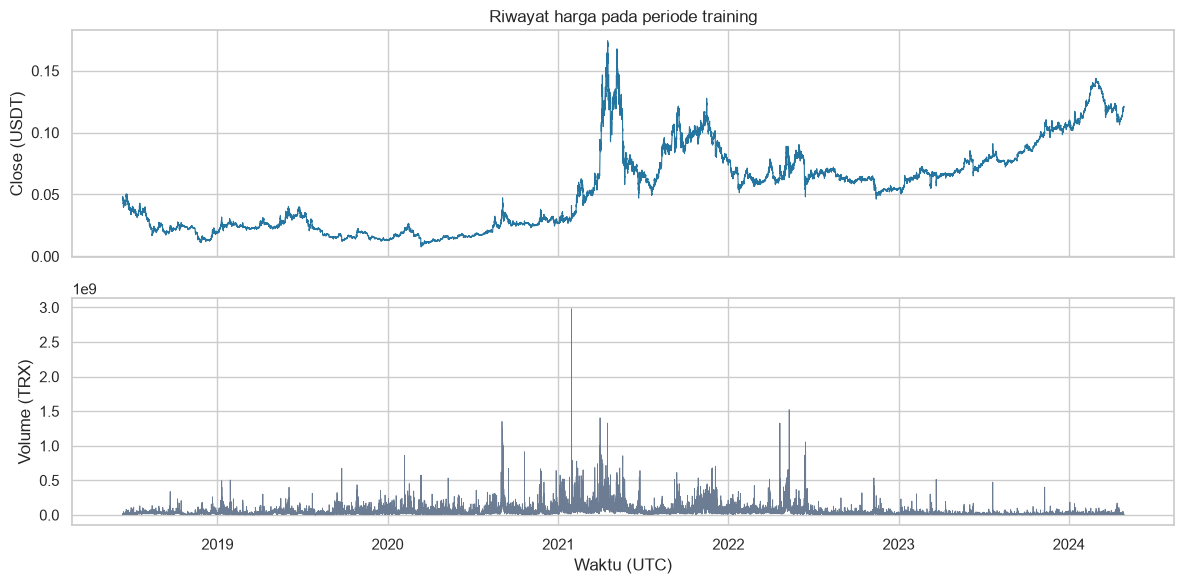

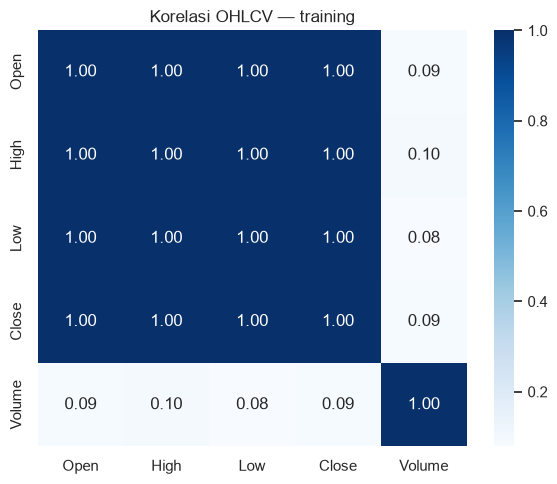

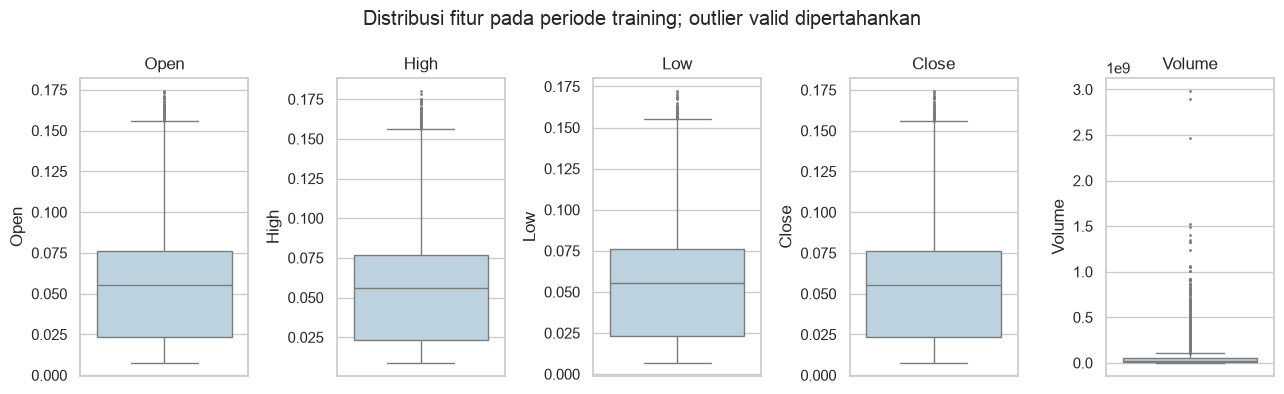

In [7]:
train_frame = df.iloc[:prepared.scaler_fit_last_index + 1]
display(train_frame[FEATURES].describe())
figures = {}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(train_frame["Open_time"], train_frame["Close"], color="#2476a0", linewidth=0.8)
axes[0].set_ylabel("Close (USDT)")
axes[0].set_title("Riwayat harga pada periode training")
axes[1].plot(train_frame["Open_time"], train_frame["Volume"], color="#6b7c93", linewidth=0.6)
axes[1].set_ylabel("Volume (TRX)")
axes[1].set_xlabel("Waktu (UTC)")
fig.tight_layout()
figures["eda_close_volume_train.png"] = fig
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(train_frame[FEATURES].corr(), annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Korelasi OHLCV — training")
fig.tight_layout()
figures["eda_correlation_train.png"] = fig
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(13, 4))
for ax, feature in zip(axes, FEATURES):
    sns.boxplot(y=train_frame[feature], ax=ax, color="#b6d4e5", fliersize=1)
    ax.set_title(feature)
fig.suptitle("Distribusi fitur pada periode training; outlier valid dipertahankan")
fig.tight_layout()
figures["eda_boxplot_train.png"] = fig
plt.show()

### 7. Arsitektur BiLSTM

Arsitektur awal: `(batch, 25, 5)` → BiLSTM 2 lapisan × 64 unit per arah →
gabungan final hidden state forward/backward 128 unit → Linear(128, 1).
BiLSTM membaca dua arah **di dalam 25 jam historis saja**. Target atau candle
setelah target tidak menjadi fitur. Implementasi model di bawah berasal dari
modul yang juga dipakai Streamlit sehingga tidak ada dua definisi model berbeda.

In [8]:
display(Code(inspect.getsource(BiLSTMRegressor), language="python"))
model_preview = BiLSTMRegressor(initial_config)
print(model_preview)
print("Jumlah parameter:", sum(p.numel() for p in model_preview.parameters()))
print("Contoh output:", tuple(model_preview(example_x.unsqueeze(0)).shape))
del model_preview

class BiLSTMRegressor(nn.Module):
    def __init__(self, config: ModelConfig):
        super().__init__()
        self.lstm = nn.LSTM(input_size=len(FEATURES), hidden_size=config.hidden_size,
                            num_layers=config.num_layers, batch_first=True,
                            bidirectional=True, dropout=config.dropout)
        self.fc = nn.Linear(config.hidden_size * 2, 1)

    def forward(self, x):
        if x.ndim != 3 or x.shape[1:] != (WINDOW_SIZE, len(FEATURES)):
            raise ValueError("Input model harus berbentuk (batch, 25, 5).")
        _, (h_n, _) = self.lstm(x)
        # Final hidden state kedua arah pada LAPISAN TERAKHIR.
        # output[:, -1, :] tidak berisi final backward state yang sama.
        context = torch.cat((h_n[-2], h_n[-1]), dim=1)
        return self.fc(context)

BiLSTMRegressor(
  (lstm): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Jumlah parameter: 135809
Contoh output: (1, 1)


### 8. Pelatihan dan pemilihan konfigurasi menggunakan validasi

Optimizer Adam, loss MSE, maksimum 100 epoch, early stopping patience 10,
gradient clipping 1.0, seed 42, dan DataLoader `shuffle=False`. Bobot epoch dengan validation loss terendah disimpan. Semua kandidat
memakai scaler serta split yang sama. RMSE validasi dalam USDT menentukan
konfigurasi terpilih. Data uji belum dievaluasi pada tahap ini.

In [20]:
if RUN_TUNING:
    tuning_log = OUTPUT_ROOT / ("tuning_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
    selected_fit, experiments = tune_model(
        prepared, initial_config, tune_dropout=TUNE_DROPOUT,
        log_dir=tuning_log, verbose=True,
    )
    display(experiments.sort_values("val_rmse_usdt").reset_index(drop=True))
else:
    print(initial_config)
    selected_fit = fit_model(prepared, initial_config, verbose=True)
    experiments = pd.DataFrame([{
        "stage": "arsitektur_awal_tanpa_penalaan", **asdict(selected_fit.config),
        "best_epoch": selected_fit.best_epoch,
        "val_rmse_usdt": selected_fit.validation_rmse_usdt,
    }])

print("Konfigurasi dikunci:")
display(pd.Series(asdict(selected_fit.config)))
print("Epoch terbaik:", selected_fit.best_epoch)
print("RMSE validasi (USDT):", selected_fit.validation_rmse_usdt)

ModelConfig(hidden_size=64, num_layers=2, dropout=0.2, batch_size=32, learning_rate=0.001, max_epochs=100, patience=10, gradient_clip=1.0, seed=42, window_size=25, horizon=1)
Epoch 001: train MSE=0.00171846; val MSE=0.40040005
Epoch 002: train MSE=0.00188214; val MSE=0.40350475
Epoch 003: train MSE=0.00227915; val MSE=0.41096851
Epoch 004: train MSE=0.00256384; val MSE=0.40846912
Epoch 005: train MSE=0.00287965; val MSE=0.40644793
Epoch 006: train MSE=0.00322112; val MSE=0.39460730
Epoch 007: train MSE=0.00254683; val MSE=0.36510581
Epoch 008: train MSE=0.00126328; val MSE=0.34033586
Epoch 009: train MSE=0.00072369; val MSE=0.31722150
Epoch 010: train MSE=0.00053300; val MSE=0.30591418
Epoch 011: train MSE=0.00048715; val MSE=0.29811452
Epoch 012: train MSE=0.00045658; val MSE=0.29393284
Epoch 013: train MSE=0.00041611; val MSE=0.28894066
Epoch 014: train MSE=0.00037779; val MSE=0.28445792
Epoch 015: train MSE=0.00034842; val MSE=0.27786025
Epoch 016: train MSE=0.00031665; val MSE=0.26

hidden_size       64.000
num_layers         2.000
dropout            0.200
batch_size        32.000
learning_rate      0.001
max_epochs       100.000
patience          10.000
gradient_clip      1.000
seed              42.000
window_size       25.000
horizon            1.000
dtype: float64

Epoch terbaik: 32
RMSE validasi (USDT): 0.06551756624601943


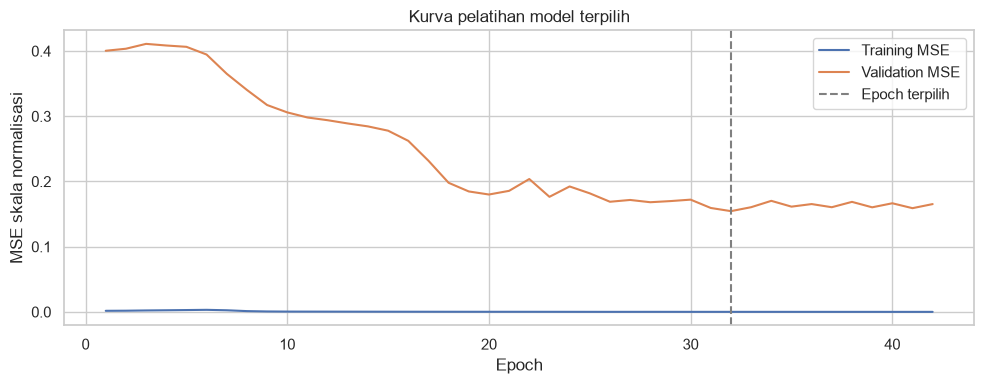

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
history = selected_fit.history
ax.plot(history["epoch"], history["train_mse_scaled"], label="Training MSE")
ax.plot(history["epoch"], history["val_mse_scaled"], label="Validation MSE")
ax.axvline(selected_fit.best_epoch, linestyle="--", color="gray", label="Epoch terpilih")
ax.set(xlabel="Epoch", ylabel="MSE skala normalisasi", title="Kurva pelatihan model terpilih")
ax.legend()
fig.tight_layout()
figures["training_loss.png"] = fig
plt.show()

### 9. Evaluasi final pada data uji

Jalankan setelah seluruh keputusan konfigurasi dikunci. Jangan memakai metrik
data uji untuk mengulangi pemilihan parameter. Prediksi dikembalikan ke USDT
sebelum menghitung MAE, RMSE, dan MAPE. `MAPE (%)` berarti nilai rasio dikali 100.
Evaluasi ini tidak menambahkan model pembanding.

In [22]:
test_metrics, test_predictions = evaluate_test(prepared, selected_fit)
display(pd.DataFrame([test_metrics]))
display(test_predictions.head())
display(test_predictions.nlargest(10, "absolute_error_usdt"))

,mae_usdt,rmse_usdt,mape_percent
0,0.144517,0.146385,45.025968


,target_open_utc,target_close_utc,actual_close_usdt,predicted_close_usdt,residual_usdt,absolute_error_usdt
0,2025-07-25 21:00:00+00:00,2025-07-25 21:59:59.999000+00:00,0.3152,0.174194,0.141006,0.141006
1,2025-07-25 22:00:00+00:00,2025-07-25 22:59:59.999000+00:00,0.3162,0.174193,0.142007,0.142007
2,2025-07-25 23:00:00+00:00,2025-07-25 23:59:59.999000+00:00,0.3170,0.174228,0.142772,0.142772
3,2025-07-26 00:00:00+00:00,2025-07-26 00:59:59.999000+00:00,0.3178,0.174250,0.143550,0.143550
4,2025-07-26 01:00:00+00:00,2025-07-26 01:59:59.999000+00:00,0.3173,0.174265,0.143035,0.143035


,target_open_utc,target_close_utc,actual_close_usdt,predicted_close_usdt,residual_usdt,absolute_error_usdt
7311,2026-05-26 12:00:00+00:00,2026-05-26 12:59:59.999000+00:00,0.3762,0.175939,0.200261,0.200261
7321,2026-05-26 22:00:00+00:00,2026-05-26 22:59:59.999000+00:00,0.3761,0.175974,0.200126,0.200126
7310,2026-05-26 11:00:00+00:00,2026-05-26 11:59:59.999000+00:00,0.3758,0.175902,0.199898,0.199898
7303,2026-05-26 04:00:00+00:00,2026-05-26 04:59:59.999000+00:00,0.3758,0.175929,0.199871,0.199871
7314,2026-05-26 15:00:00+00:00,2026-05-26 15:59:59.999000+00:00,0.3758,0.175964,0.199836,0.199836
7322,2026-05-26 23:00:00+00:00,2026-05-26 23:59:59.999000+00:00,0.3756,0.175990,0.199610,0.199610
7312,2026-05-26 13:00:00+00:00,2026-05-26 13:59:59.999000+00:00,0.3755,0.175992,0.199508,0.199508
7320,2026-05-26 21:00:00+00:00,2026-05-26 21:59:59.999000+00:00,0.3754,0.175958,0.199442,0.199442
7313,2026-05-26 14:00:00+00:00,2026-05-26 14:59:59.999000+00:00,0.3753,0.175974,0.199326,0.199326
7324,2026-05-27 01:00:00+00:00,2026-05-27 01:59:59.999000+00:00,0.3751,0.175973,0.199127,0.199127


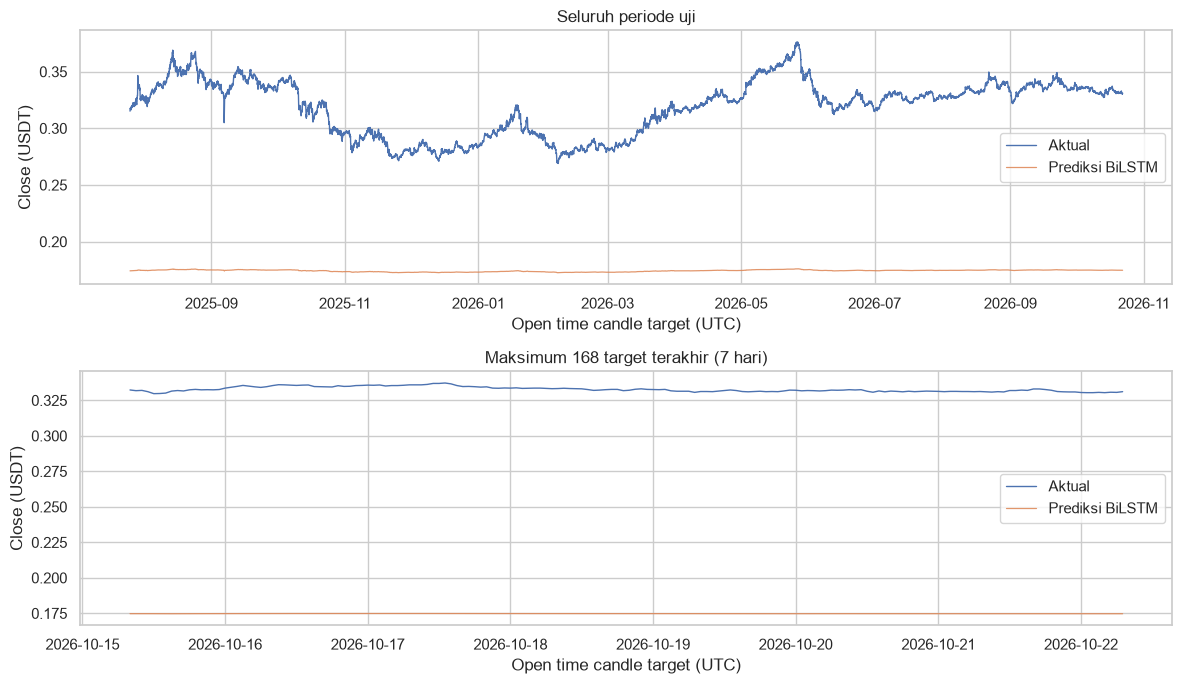

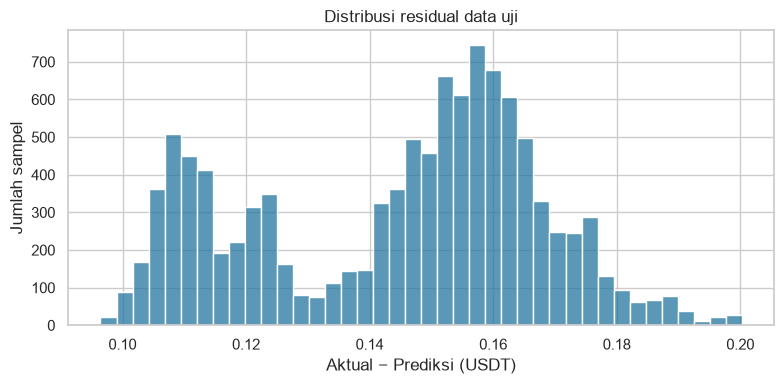

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, table, title in [
    (axes[0], test_predictions, "Seluruh periode uji"),
    (axes[1], test_predictions.tail(168), "Maksimum 168 target terakhir (7 hari)"),
]:
    ax.plot(pd.to_datetime(table["target_open_utc"], utc=True), table["actual_close_usdt"], label="Aktual", linewidth=1)
    ax.plot(pd.to_datetime(table["target_open_utc"], utc=True), table["predicted_close_usdt"], label="Prediksi BiLSTM", linewidth=0.9, alpha=0.85)
    ax.set(title=title, ylabel="Close (USDT)", xlabel="Open time candle target (UTC)")
    ax.legend()
fig.tight_layout()
figures["actual_vs_prediction_test.png"] = fig
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(test_predictions["residual_usdt"], bins=40, ax=ax, color="#2476a0")
ax.set(title="Distribusi residual data uji", xlabel="Aktual − Prediksi (USDT)", ylabel="Jumlah sampel")
fig.tight_layout()
figures["residuals_test.png"] = fig
plt.show()

### 10. Simpan model, scaler, dataset snapshot, metrik, dan grafik

Setiap pelatihan mempunyai versi baru. Streamlit memuat artefak dari folder
yang sama dan tidak melatih ulang saat tombol prediksi ditekan. Scaler disimpan
sebagai parameter JSON; bobot sebagai PyTorch `state_dict`. SHA-256 dan nomor
versi memeriksa kecocokan model, scaler, dan snapshot dataset.

In [24]:
run_dir = save_bundle(
    OUTPUT_ROOT, prepared, selected_fit, test_metrics, test_predictions,
    source_metadata=source_metadata, quality_report=quality_report,
    experiments=experiments,
)
fig_dir = run_dir / "figures"
fig_dir.mkdir(exist_ok=True)
for name, figure in figures.items():
    figure.savefig(fig_dir / name, dpi=160, bbox_inches="tight")
write_json(run_dir / "experiment_mode.json", {"run_tuning": RUN_TUNING, "tune_dropout": TUNE_DROPOUT})
print("Semua artefak disimpan pada:", run_dir.resolve())
display(pd.Series(test_metrics, name="hasil_final_data_uji"))

Semua artefak disimpan pada: /Users/reefu/Downloads/trx_bilstm_1h_25/artifacts/trx_1h_w25_20261022T093132880076Z


mae_usdt         0.144517
rmse_usdt        0.146385
mape_percent    45.025968
Name: hasil_final_data_uji, dtype: float64

### 11. Inferensi dengan memuat ulang model tersimpan

Jika candle input terakhir mempunyai Open time 09:00 UTC dan selesai
09:59:59.999 UTC, targetnya adalah Close candle 10:00–10:59:59.999 UTC.
Timestamp prediksi selalu mengikuti akhir dataset, sehingga memakai snapshot
lama tidak otomatis menjadi prediksi pasar terbaru.

In [25]:
bundle = load_bundle(run_dir)
next_prediction = predict_next(bundle, df)
display(pd.Series({k: v for k, v in next_prediction.items() if k != "quality_report"}))
print(f"Prediksi Close: {next_prediction['predicted_close_usdt']:.6f} USDT")
print("Candle target:", next_prediction["target_open_utc"], "sampai", next_prediction["target_close_utc"])

predicted_close_usdt                                        0.174736
last_input_open_utc                        2026-10-22T07:00:00+00:00
last_input_close_utc                2026-10-22T07:59:59.999000+00:00
target_open_utc                            2026-10-22T08:00:00+00:00
target_close_utc                    2026-10-22T08:59:59.999000+00:00
model_version                      trx_1h_w25_20261022T093132880076Z
inference_seconds                                           0.001301
features_outside_training_range                                  100
dtype: object

Prediksi Close: 0.174736 USDT
Candle target: 2026-10-22T08:00:00+00:00 sampai 2026-10-22T08:59:59.999000+00:00


### 12. Tampilkan melalui Streamlit

```bash
python -m streamlit run app.py
```

RMSE, MAE, MAPE rendah kemungkinan karena belum tuning hyperparameter, akan segera saya lakukan tuning saat servis laptop selesai buu...

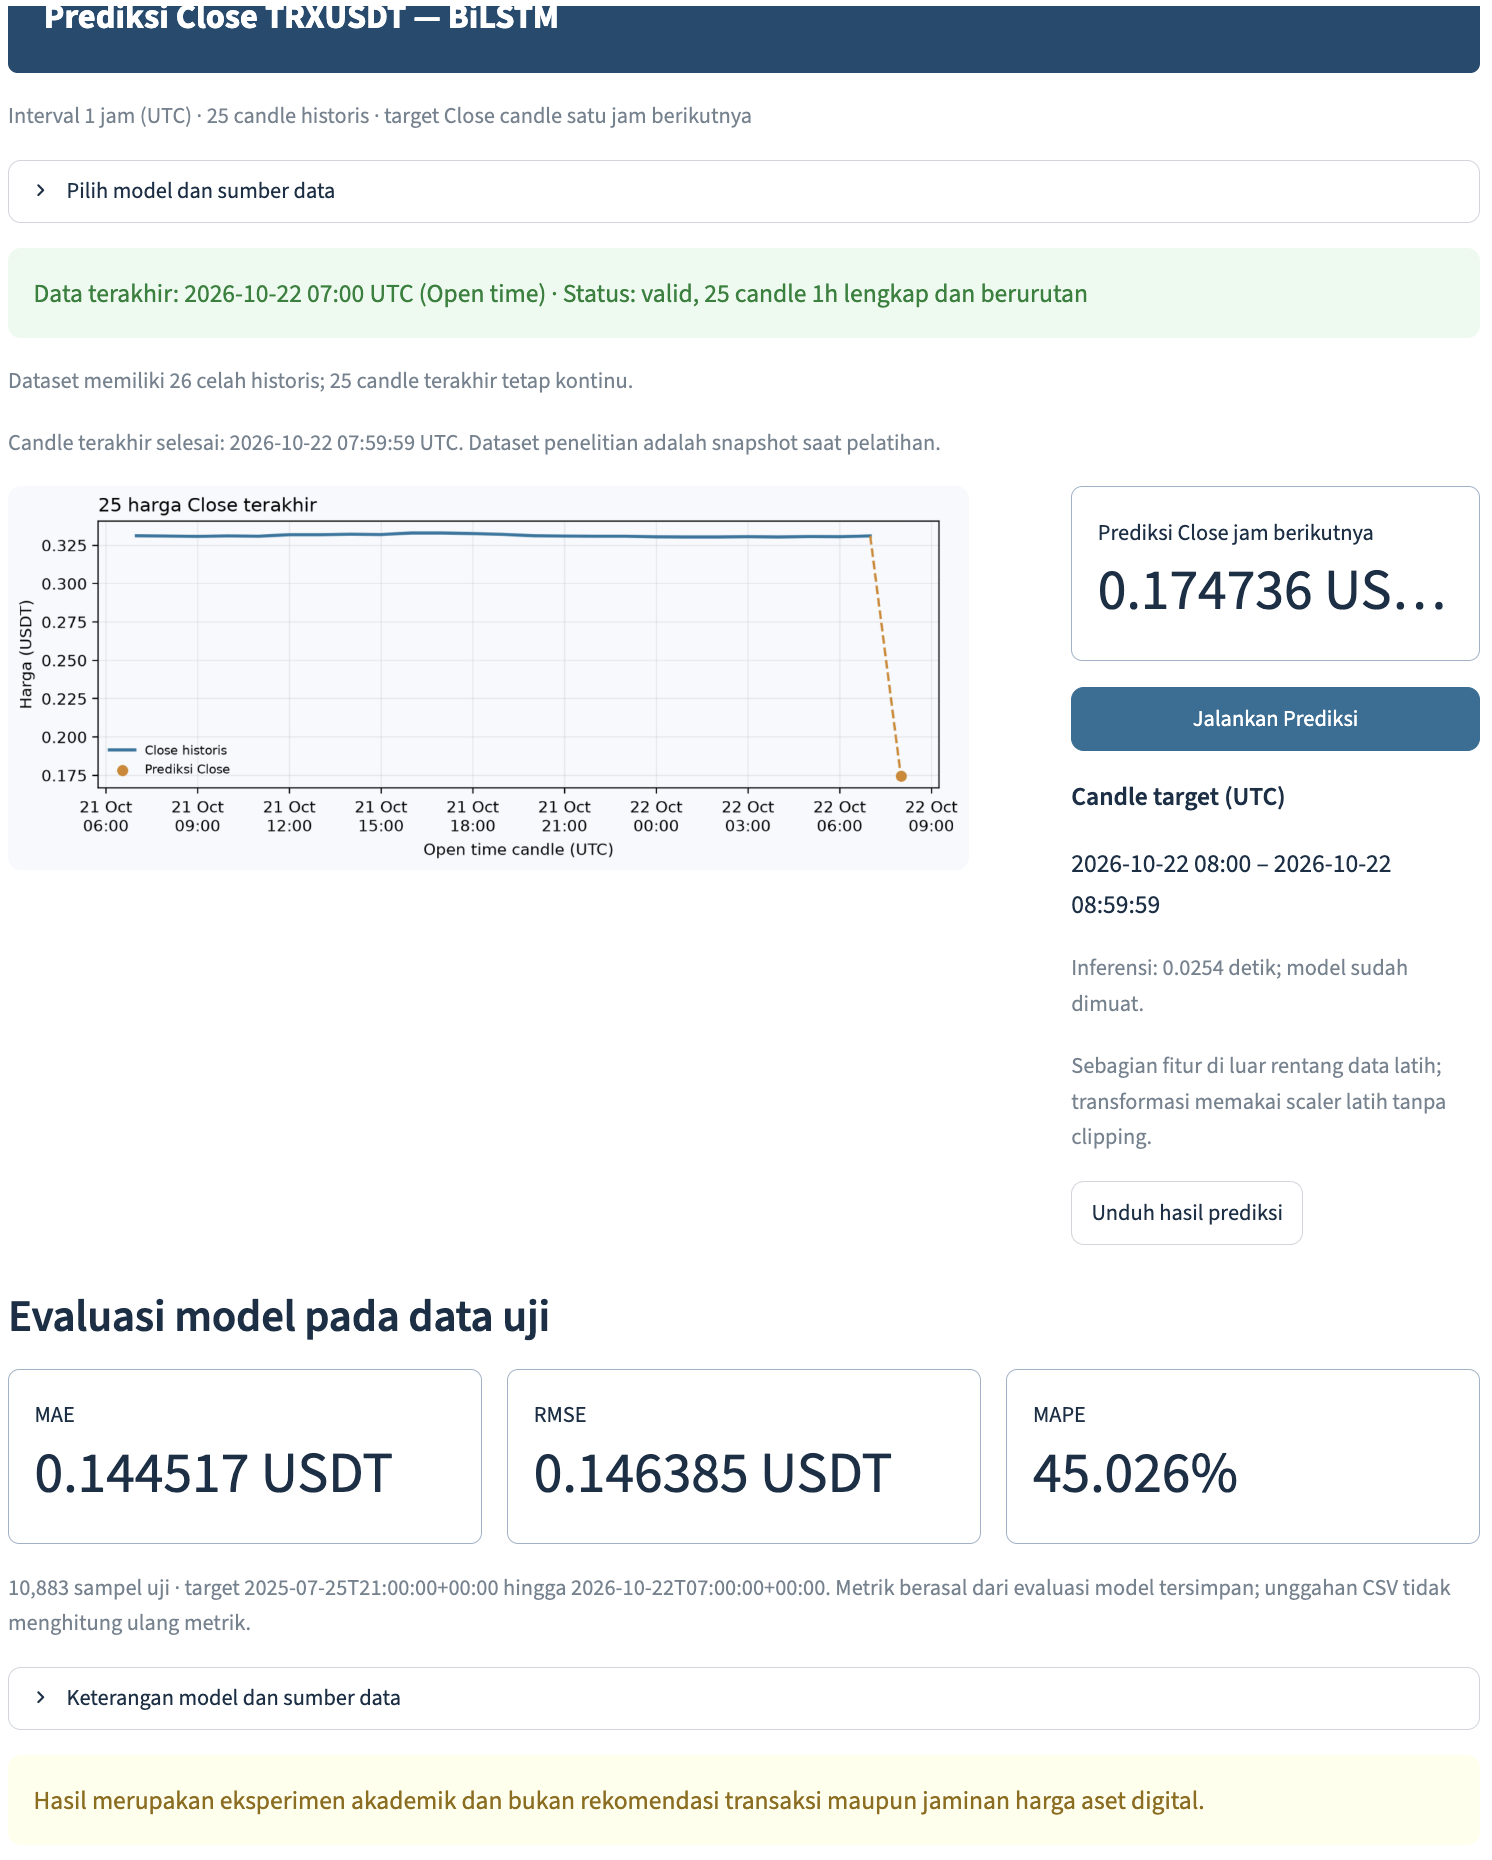

